### References

*   **GEKKO Optimization Suite Article:**
    Beal, L. D. R., Hill, D., Martin, R. A., & Hedengren, J. D. (2018). *GEKKO Optimization Suite*. Processes, 6(8), 106. doi.org

*   **APMonitor Course Website (ME575):**
    Hedengren, J. D. (n.d.). *Design Optimization (ME 575)*. APMonitor. Retrieved January 9, 2026, from https://apmonitor.com/me575/index.php/Main/HomePage

*   **Mr. P Solver (YouTube Channel):**
    Mr. P Solver. (n.d.). *Home* [YouTube channel]. YouTube. Retrieved January 9, 2026, from https://www.youtube.com/@MrPSolver

*   **The OR Book (Textbook):**
    Winston, W. L. (2004). *Operations Research: Applications and Algorithms* (4th ed.). Thomson Brooks/Cole.


then see according to this website:Engineering Optimization https://apmonitor.com/me575/index.php/Main/HomePage

**intro**


see file from analytics vidhya for data manupulation on introduction to python and machine leraninng course files:

here are my local file paths: C:\Users\User\Desktop\00011jupyter\other practice file\introToMachine learningfron vidhya

this meant to handle this quetion: now , just give me a jupyter markdown code to read and refer to explaining these: how to handle data for processing and manipulation( especcially with large data sets and large number of quations) for tasks such as optimization using gekko ,scipy etc etc

the soved homeworks
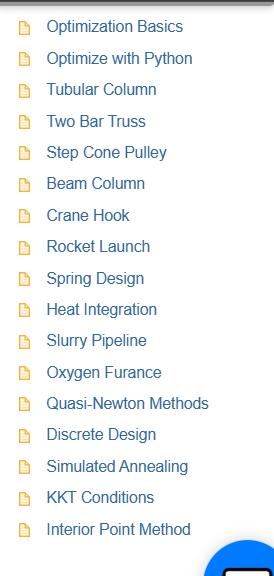

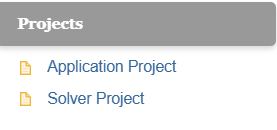

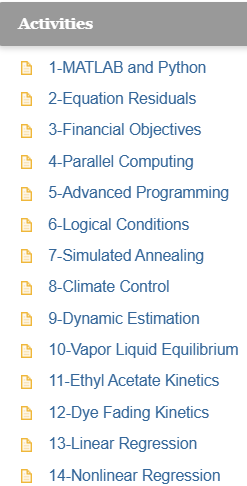
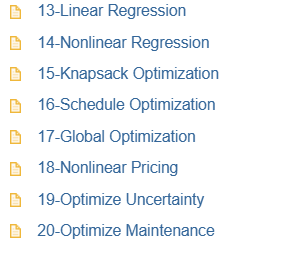

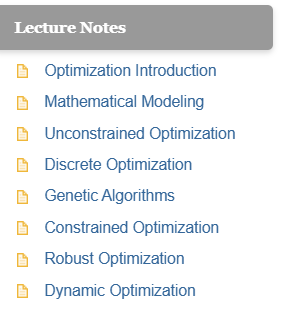

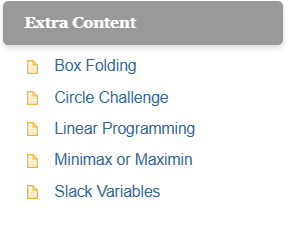

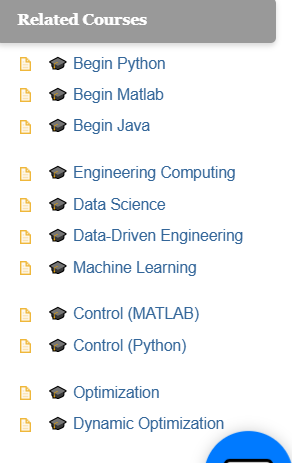

In [9]:
# -------------------------------------------------------------
# LINEAR PROGRAMMING WITH PULP (FREE)
# -------------------------------------------------------------
# This code replicates your DOcplex model using PuLP + CBC solver.
# Variables, constraints, and objective work exactly like DOcplex.
# -------------------------------------------------------------

import pulp

# Create the LP problem (we are maximizing profit)
model = pulp.LpProblem("Phone_Production", pulp.LpMaximize)

# Decision variables
# LowBound=0 ensures they are continuous and non-negative
foldyphone = pulp.LpVariable("foldyphone", lowBound=0, cat='Continuous')
tinyphone = pulp.LpVariable("tinyphone", lowBound=0, cat='Continuous')

# Constants
foldyphonetime = 1.5
tinyphonetime = 2

# Production minimum constraints
model += (foldyphone >= 500, "Foldyphone_minimum")
model += (tinyphone >= 200, "Tinyphone_minimum")

# Total assembly time constraint
model += (foldyphone * foldyphonetime +
          tinyphone * tinyphonetime <= 2999.5,
          "Total_time_limit")

# Objective function: maximize revenue
model += foldyphone * 900 + tinyphone * 1100

# Solve the model using CBC (comes with PuLP)
model.solve(pulp.PULP_CBC_CMD())

# Display results
print("Status:", pulp.LpStatus[model.status])
print("Optimal foldyphone:", foldyphone.value())
print("Optimal tinyphone:", tinyphone.value())
print("Maximum profit:", pulp.value(model.objective))


Status: Optimal
Optimal foldyphone: 1733.0
Optimal tinyphone: 200.0
Maximum profit: 1779700.0


In [11]:
# -------------------------------------------------------------
# LINEAR PROGRAMMING WITH OR-TOOLS (FREE)
# -------------------------------------------------------------
# This uses Google OR-Tools with the HiGHS solver.
# Same problem: maximize profit from producing two phones.
# -------------------------------------------------------------

from ortools.linear_solver import pywraplp

# Create solver using HiGHS (free LP/MIP solver)
solver = pywraplp.Solver.CreateSolver("HiGHS")

# Decision variables (continuous and >= 0)
foldyphone = solver.NumVar(0.0, solver.infinity(), "foldyphone")
tinyphone   = solver.NumVar(0.0, solver.infinity(), "tinyphone")

# Constants
foldyphonetime = 1.5
tinyphonetime = 2

# Production minimums
solver.Add(foldyphone >= 500)
solver.Add(tinyphone >= 200)

# Total time constraint
solver.Add(foldyphone * foldyphonetime +
           tinyphone * tinyphonetime <= 2999.5)

# Objective function
objective = solver.Objective()
objective.SetCoefficient(foldyphone, 900)
objective.SetCoefficient(tinyphone, 1100)
objective.SetMaximization()

# Solve
result_status = solver.Solve()

# Display results
if result_status == pywraplp.Solver.OPTIMAL:
    print("Optimal solution found:")
    print("foldyphone =", foldyphone.solution_value())
    print("tinyphone =", tinyphone.solution_value())
    print("Maximum profit =", objective.Value())
else:
    print("No optimal solution found.")


Optimal solution found:
foldyphone = 1733.0
tinyphone = 200.0
Maximum profit = 1779700.0


OR book pg68
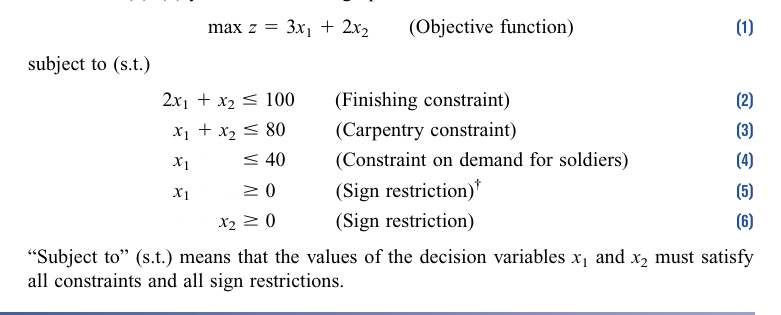

# 🧠 GEKKO Linear Programming: Complete Guide
*A Jupyter Notebook Tutorial*

## 📚 Table of Contents
1. [Introduction to GEKKO](#introduction)
2. [Basic Setup](#setup)
3. [Defining Variables](#variables)
4. [Objective Function](#objective)
5. [Constraints Handling](#constraints)
6. [Complete Template](#template)
7. [Examples](#examples)
8. [Troubleshooting](#troubleshooting)

---

## 1. Introduction to GEKKO <a name="introduction"></a>

**GEKKO** is a Python optimization library that:
- Solves LP, QP, NLP, MILP, MINLP problems
- Has local (APOPT, IPOPT) and remote solvers
- Supports dynamic and steady-state optimization

### Installation
```bash
pip install gekko

 Basic model initialization
 
m = GEKKO(remote=False)  # Use local solver (faster)

m.options.SOLVER = 1      # 1=APOPT, 3=IPOPT

m.options.IMODE = 3       # Steady-state optimization

etc

LINEAR PROGRAMMING SOLUTION

Objective: Maximize z = 3x₁ + 2x₂

Constraints:
  1. 2x₁ + x₂ ≤ 100 (Finishing)
  2. x₁ + x₂ ≤ 80 (Carpentry)
  3. x₁ ≤ 40 (Demand for soldiers)
  4. x₁ ≥ 0, x₂ ≥ 0


✅ OPTIMAL SOLUTION FOUND

Optimal values:
  x₁ (soldiers) = 20.00
  x₂ (trains)   = 60.00

Maximum profit: z = 180.00

Shadow prices (marginal values of constraints):
  Finishing constraint: 0.00 unused hours
  Carpentry constraint: 0.00 unused hours
  Demand constraint:    20.00 unused capacity

Dual values (constraint sensitivity):
  Finishing: -1.00
  Carpentry: -1.00
  Demand:    -0.00

VISUALIZATION OF FEASIBLE REGION


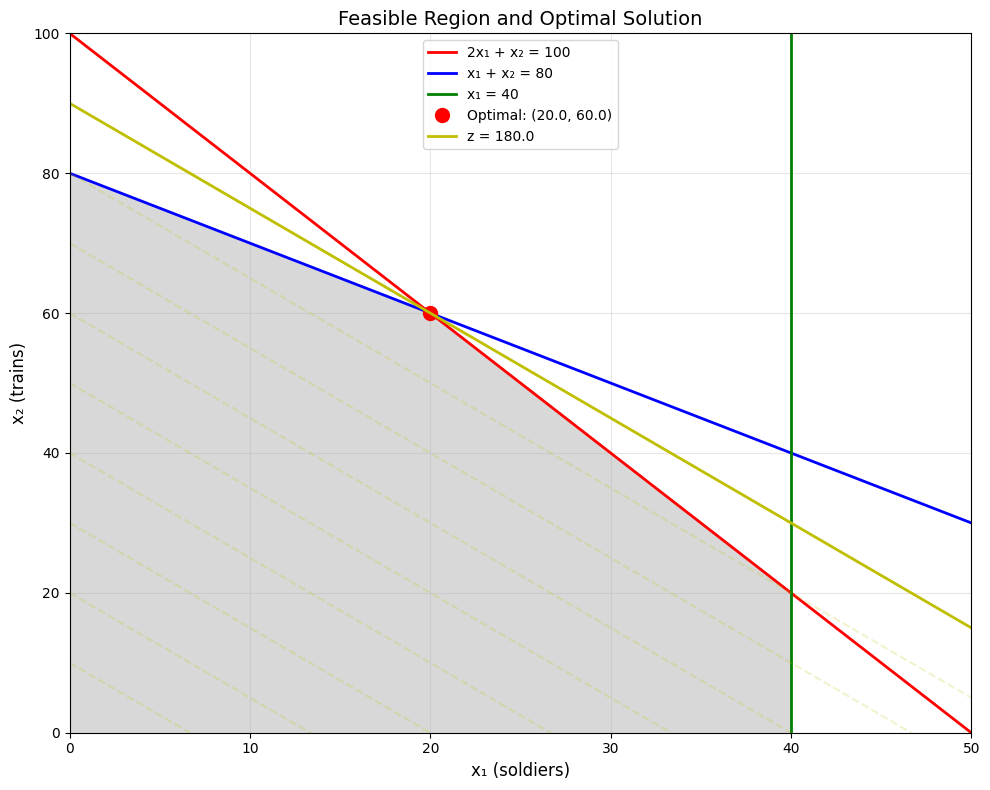


Corner Points Analysis:
----------------------------------------
  (0, 0): z = 0
  (40, 0): z = 120
  (0, 80): z = 160
  (20, 60): z = 180
  (40, 20): z = 160

✓ Optimal: (20.0, 60.0): z = 180.0


In [10]:
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt

# Coefficients for the objective function (maximize 3x1 + 2x2)
# We'll convert to minimization: maximize c·x = minimize -c·x
c = [-3, -2]  # Negative because we maximize

# Inequality constraints (A_ub * x <= b_ub)
A_ub = [
    [2, 1],   # 2x1 + x2 <= 100
    [1, 1],   # x1 + x2 <= 80
    [1, 0]    # x1 <= 40
]
b_ub = [100, 80, 40]

# Bounds for variables
x_bounds = (0, None)  # x1 >= 0
y_bounds = (0, None)  # x2 >= 0

# Solve the linear programming problem
result = linprog(c, A_ub=A_ub, b_ub=b_ub, bounds=[x_bounds, y_bounds], method='highs')

# Display results
print("=" * 50)
print("LINEAR PROGRAMMING SOLUTION")
print("=" * 50)
print(f"\nObjective: Maximize z = 3x₁ + 2x₂")
print(f"\nConstraints:")
print(f"  1. 2x₁ + x₂ ≤ 100 (Finishing)")
print(f"  2. x₁ + x₂ ≤ 80 (Carpentry)")
print(f"  3. x₁ ≤ 40 (Demand for soldiers)")
print(f"  4. x₁ ≥ 0, x₂ ≥ 0")
print("\n" + "=" * 50)

if result.success:
    print(f"\n✅ OPTIMAL SOLUTION FOUND")
    print(f"\nOptimal values:")
    print(f"  x₁ (soldiers) = {result.x[0]:.2f}")
    print(f"  x₂ (trains)   = {result.x[1]:.2f}")
    print(f"\nMaximum profit: z = { -result.fun:.2f}")  # Negative because we minimized -z
    
    # Shadow prices (dual values)
    print(f"\nShadow prices (marginal values of constraints):")
    print(f"  Finishing constraint: {result.slack[0]:.2f} unused hours")
    print(f"  Carpentry constraint: {result.slack[1]:.2f} unused hours")
    print(f"  Demand constraint:    {result.slack[2]:.2f} unused capacity")
    
    # Dual values (sensitivity analysis)
    if hasattr(result, 'ineqlin'):
        print(f"\nDual values (constraint sensitivity):")
        print(f"  Finishing: {result.ineqlin.marginals[0]:.2f}")
        print(f"  Carpentry: {result.ineqlin.marginals[1]:.2f}")
        print(f"  Demand:    {result.ineqlin.marginals[2]:.2f}")
else:
    print(f"\n❌ NO OPTIMAL SOLUTION FOUND")
    print(f"Status: {result.message}")

# Visualize the feasible region (optional)
print("\n" + "=" * 50)
print("VISUALIZATION OF FEASIBLE REGION")
print("=" * 50)

# Create a grid of x1 and x2 values
x1 = np.linspace(0, 50, 400)
x2 = np.linspace(0, 100, 400)

# Create meshgrid
X1, X2 = np.meshgrid(x1, x2)

# Constraints
C1 = 2*X1 + X2 <= 100  # Finishing
C2 = X1 + X2 <= 80     # Carpentry
C3 = X1 <= 40          # Demand
C4 = X1 >= 0           # Non-negativity
C5 = X2 >= 0           # Non-negativity

# Feasible region
feasible = C1 & C2 & C3 & C4 & C5

if result.success:
    # Plot
    plt.figure(figsize=(10, 8))
    
    # Plot feasible region
    plt.contourf(X1, X2, feasible, levels=[0.5, 1], alpha=0.3, colors='gray')
    
    # Plot constraints as lines
    x1_line = np.linspace(0, 50, 100)
    
    # Constraint 1: 2x1 + x2 = 100
    plt.plot(x1_line, 100 - 2*x1_line, 'r-', label='2x₁ + x₂ = 100', linewidth=2)
    
    # Constraint 2: x1 + x2 = 80
    plt.plot(x1_line, 80 - x1_line, 'b-', label='x₁ + x₂ = 80', linewidth=2)
    
    # Constraint 3: x1 = 40
    plt.axvline(x=40, color='g', linestyle='-', label='x₁ = 40', linewidth=2)
    
    # Plot optimal point
    plt.plot(result.x[0], result.x[1], 'ro', markersize=10, label=f'Optimal: ({result.x[0]:.1f}, {result.x[1]:.1f})')
    
    # Plot objective function contours
    if result.success:
        # Create contours for objective function
        z_vals = np.linspace(0, 180, 10)
        for z in z_vals:
            x2_obj = (z - 3*x1_line) / 2
            plt.plot(x1_line, x2_obj, 'y--', alpha=0.2)
        
        # Highlight optimal contour
        optimal_z = -result.fun
        x2_opt = (optimal_z - 3*x1_line) / 2
        plt.plot(x1_line, x2_opt, 'y-', linewidth=2, label=f'z = {optimal_z:.1f}')
    
    plt.xlabel('x₁ (soldiers)', fontsize=12)
    plt.ylabel('x₂ (trains)', fontsize=12)
    plt.title('Feasible Region and Optimal Solution', fontsize=14)
    plt.xlim([0, 50])
    plt.ylim([0, 100])
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    # Display corner points
    print("\nCorner Points Analysis:")
    print("-" * 40)
    
    # Calculate all corner points
    corners = [
        (0, 0),          # Origin
        (40, 0),         # x1 max, x2=0
        (0, 80),         # x2 max (subject to x1+x2<=80)
        (20, 60),        # Intersection of 2x1+x2=100 and x1+x2=80
        (40, 20),        # Intersection of x1=40 and 2x1+x2=100
        (40, 40)         # Intersection of x1=40 and x1+x2=80 (but check feasibility)
    ]
    
    # Filter feasible corners
    feasible_corners = []
    for x1_val, x2_val in corners:
        if (2*x1_val + x2_val <= 100 + 1e-6 and 
            x1_val + x2_val <= 80 + 1e-6 and 
            x1_val <= 40 + 1e-6 and
            x1_val >= 0 - 1e-6 and 
            x2_val >= 0 - 1e-6):
            feasible_corners.append((x1_val, x2_val))
            z_val = 3*x1_val + 2*x2_val
            print(f"  ({x1_val}, {x2_val}): z = {z_val}")
    
    # Highlight optimal
    print(f"\n✓ Optimal: ({result.x[0]:.1f}, {result.x[1]:.1f}): z = {-result.fun:.1f}")

In [12]:
# Alternative solution using PuLP
from pulp import LpProblem, LpMaximize, LpVariable, LpStatus, value

# Create the problem
prob = LpProblem("Toy_Company_Profit", LpMaximize)

# Decision variables
x1 = LpVariable("x1", lowBound=0, cat='Continuous')  # soldiers
x2 = LpVariable("x2", lowBound=0, cat='Continuous')  # trains

# Objective function
prob += 3*x1 + 2*x2, "Total Profit"

# Constraints
prob += 2*x1 + x2 <= 100, "Finishing_constraint"
prob += x1 + x2 <= 80, "Carpentry_constraint"
prob += x1 <= 40, "Demand_constraint"

# Solve
prob.solve()

# Display results
print("\n" + "="*50)
print("PULP SOLUTION")
print("="*50)
print(f"Status: {LpStatus[prob.status]}")
print(f"Optimal Solution:")
print(f"  x1 (soldiers) = {value(x1):.2f}")
print(f"  x2 (trains)   = {value(x2):.2f}")
print(f"Maximum Profit  = ${value(prob.objective):.2f}")

# Shadow prices (dual values)
print("\nShadow Prices:")
for name, constraint in prob.constraints.items():
    print(f"  {name}: {constraint.pi:.2f}")


PULP SOLUTION
Status: Optimal
Optimal Solution:
  x1 (soldiers) = 20.00
  x2 (trains)   = 60.00
Maximum Profit  = $180.00

Shadow Prices:
  Finishing_constraint: 1.00
  Carpentry_constraint: 1.00
  Demand_constraint: -0.00


In [14]:
from gekko import GEKKO
import numpy as np

# Create GEKKO model
m = GEKKO(remote=False)

# Define variables
x1 = m.Var(lb=0, name='x1')  # soldiers, lower bound 0
x2 = m.Var(lb=0, name='x2')  # trains, lower bound 0

# Define objective function (maximize 3x1 + 2x2)
# GEKKO minimizes by default, so we minimize -objective
m.Obj(-(3*x1 + 2*x2))

# Add constraints
m.Equation(2*x1 + x2 <= 100)  # Finishing constraint
m.Equation(x1 + x2 <= 80)     # Carpentry constraint
m.Equation(x1 <= 40)          # Demand constraint

# Set solver options (optional)
m.options.SOLVER = 1  # 1=APOPT, 3=IPOPT
m.options.IMODE = 3   # Steady state optimization

# Solve
print("=" * 60)
print("SOLVING LINEAR PROGRAMMING PROBLEM WITH GEKKO")
print("=" * 60)
print("\nProblem Formulation:")
print("Maximize: z = 3x₁ + 2x₂")
print("Subject to:")
print("  2x₁ + x₂ ≤ 100  (Finishing)")
print("  x₁ + x₂ ≤ 80    (Carpentry)")
print("  x₁ ≤ 40         (Demand)")
print("  x₁ ≥ 0, x₂ ≥ 0")

try:
    m.solve(disp=True)
    
    print("\n" + "=" * 60)
    print("SOLUTION RESULTS")
    print("=" * 60)
    
    # Get results
    x1_opt = x1.value[0]
    x2_opt = x2.value[0]
    z_opt = 3*x1_opt + 2*x2_opt
    
    print(f"\n✅ OPTIMAL SOLUTION FOUND")
    print(f"\nDecision Variables:")
    print(f"  x₁ (soldiers) = {x1_opt:.4f}")
    print(f"  x₂ (trains)   = {x2_opt:.4f}")
    print(f"\nObjective Value:")
    print(f"  Maximum profit z = {z_opt:.4f}")
    
    # Display constraint usage
    print(f"\nConstraint Analysis:")
    print(f"  1. Finishing (2x₁ + x₂ ≤ 100): {2*x1_opt + x2_opt:.2f} ≤ 100")
    print(f"  2. Carpentry (x₁ + x₂ ≤ 80):   {x1_opt + x2_opt:.2f} ≤ 80")
    print(f"  3. Demand (x₁ ≤ 40):           {x1_opt:.2f} ≤ 40")
    
    # Calculate slack/surplus
    slack1 = 100 - (2*x1_opt + x2_opt)
    slack2 = 80 - (x1_opt + x2_opt)
    slack3 = 40 - x1_opt
    
    print(f"\nSlack Variables (unused resources):")
    print(f"  Finishing constraint slack: {slack1:.4f}")
    print(f"  Carpentry constraint slack: {slack2:.4f}")
    print(f"  Demand constraint slack:    {slack3:.4f}")
    
    # Check if constraint is binding
    print(f"\nBinding Constraints (slack = 0):")
    if abs(slack1) < 1e-6:
        print("  ✓ Finishing constraint is binding")
    if abs(slack2) < 1e-6:
        print("  ✓ Carpentry constraint is binding")
    if abs(slack3) < 1e-6:
        print("  ✓ Demand constraint is binding")
    
    # Sensitivity analysis (dual prices)
    print(f"\nSensitivity Analysis:")
    print("(Note: For dual prices, use m.options.DIAGLEVEL=1 for more info)")
    
except Exception as e:
    print(f"\n❌ ERROR: {e}")
    print("Make sure GEKKO is properly installed.")

# Additional: Solve with different methods and compare
print("\n" + "=" * 60)
print("COMPARISON WITH ALTERNATIVE SOLVERS")
print("=" * 60)

# Try different solvers
solvers = [1, 3]  # 1=APOPT, 3=IPOPT
solver_names = {1: "APOPT", 3: "IPOPT"}

for solver in solvers:
    m2 = GEKKO(remote=False)
    x1_s = m2.Var(lb=0)
    x2_s = m2.Var(lb=0)
    m2.Obj(-(3*x1_s + 2*x2_s))
    m2.Equation(2*x1_s + x2_s <= 100)
    m2.Equation(x1_s + x2_s <= 80)
    m2.Equation(x1_s <= 40)
    m2.options.SOLVER = solver
    m2.options.IMODE = 3
    m2.solve(disp=False)
    
    if m2.options.SOLVESTATUS == 1:
        print(f"\n{solver_names[solver]} Solver:")
        print(f"  x₁ = {x1_s.value[0]:.4f}, x₂ = {x2_s.value[0]:.4f}")
        print(f"  z = {3*x1_s.value[0] + 2*x2_s.value[0]:.4f}")
    else:
        print(f"\n{solver_names[solver]} Solver failed to find optimal solution")

print("\n" + "=" * 60)
print("PROBLEM INTERPRETATION")
print("=" * 60)
print("\nThis is a classic toy company problem where:")
print("• x₁ represents number of soldiers produced")
print("• x₂ represents number of trains produced")
print("• Each soldier yields $3 profit, each train yields $2 profit")
print("• Constraints represent resource limitations:")
print("  - Finishing department: 100 hours available")
print("  - Carpentry department: 80 hours available")
print("  - Soldier demand: maximum 40 units")
print("\nThe optimal production plan balances these constraints to maximize profit.")

SOLVING LINEAR PROGRAMMING PROBLEM WITH GEKKO

Problem Formulation:
Maximize: z = 3x₁ + 2x₂
Subject to:
  2x₁ + x₂ ≤ 100  (Finishing)
  x₁ + x₂ ≤ 80    (Carpentry)
  x₁ ≤ 40         (Demand)
  x₁ ≥ 0, x₂ ≥ 0
 ----------------------------------------------------------------
 APMonitor, Version 1.0.3
 APMonitor Optimization Suite
 ----------------------------------------------------------------
 
 
 --------- APM Model Size ------------
 Each time step contains
   Objects      :  0
   Constants    :  0
   Variables    :  5
   Intermediates:  0
   Connections  :  0
   Equations    :  4
   Residuals    :  4
 
 Number of state variables:    5
 Number of total equations: -  3
 Number of slack variables: -  3
 ---------------------------------------
 Degrees of freedom       :    -1
 
 * Warning: DOF <= 0
 ----------------------------------------------
 Steady State Optimization with APOPT Solver
 ----------------------------------------------
 
 Iter    Objective  Convergence
    0 -1.56583E

Solving Linear Programming Problem with GEKKO...

LINEAR PROGRAMMING SOLUTION - TOY COMPANY PROBLEM

📊 OPTIMAL SOLUTION:
----------------------------------------------------------------------
     Variable    Value                   Description
x₁ (soldiers)  20.0000 Number of soldiers to produce
  x₂ (trains)  60.0000   Number of trains to produce
Objective (z) 180.0000              Total profit ($)


🔧 CONSTRAINT ANALYSIS:
----------------------------------------------------------------------
                Constraint  Left Side  Right Side   Slack      Status
Finishing (2x₁ + x₂ ≤ 100)   100.0000         100  0.0000     Binding
  Carpentry (x₁ + x₂ ≤ 80)    80.0000          80  0.0000     Binding
          Demand (x₁ ≤ 40)    20.0000          40 20.0000 Not Binding


📈 INTERPRETATION:
----------------------------------------------------------------------
To maximize profit, the company should produce:
  • 20 soldiers (x₁)
  • 60 trains (x₂)

This yields a maximum profit of $180.00



Would you like to see the feasible region visualization? (y/n):  y


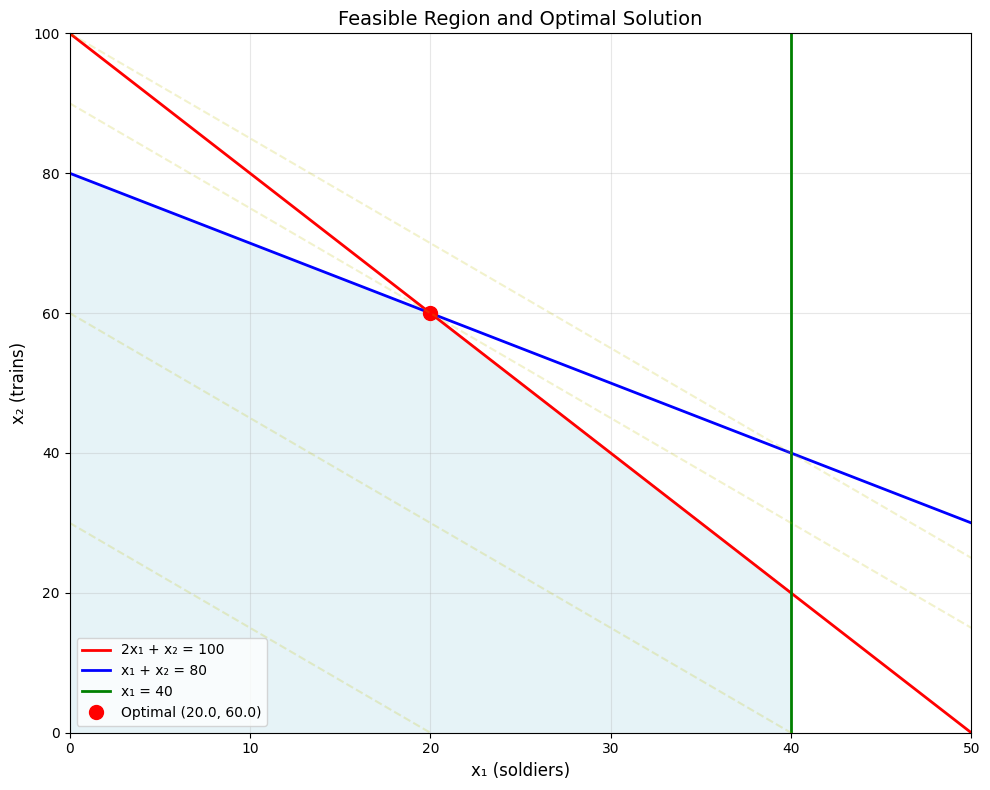

In [16]:
from gekko import GEKKO
import pandas as pd

def solve_lp_gekko():
    """Solve linear programming problem using GEKKO"""
    
    # Initialize model
    m = GEKKO(remote=False)
    
    # Variables with bounds
    x1 = m.Var(lb=0, ub=40, name='soldiers')  # ub from demand constraint
    x2 = m.Var(lb=0, name='trains')
    
    # Objective: Maximize 3x1 + 2x2
    # Convert to minimization: minimize -(3x1 + 2x2)
    m.Minimize(-(3*x1 + 2*x2))
    
    # Constraints
    m.Equation(2*x1 + x2 <= 100)  # Finishing
    m.Equation(x1 + x2 <= 80)     # Carpentry
    
    # Solver settings
    m.options.SOLVER = 1  # APOPT solver
    m.options.IMODE = 3   # Steady state optimization
    
    # Solve
    m.solve(disp=False)
    
    return m, x1, x2

def analyze_solution(m, x1, x2):
    """Analyze and display the solution"""
    
    # Extract values
    x1_val = x1.value[0]
    x2_val = x2.value[0]
    z_val = 3*x1_val + 2*x2_val
    
    # Create results dictionary
    results = {
        'Variable': ['x₁ (soldiers)', 'x₂ (trains)', 'Objective (z)'],
        'Value': [x1_val, x2_val, z_val],
        'Description': [
            'Number of soldiers to produce',
            'Number of trains to produce',
            'Total profit ($)'
        ]
    }
    
    # Constraint analysis
    constraints = {
        'Constraint': ['Finishing (2x₁ + x₂ ≤ 100)', 
                      'Carpentry (x₁ + x₂ ≤ 80)', 
                      'Demand (x₁ ≤ 40)'],
        'Left Side': [2*x1_val + x2_val, x1_val + x2_val, x1_val],
        'Right Side': [100, 80, 40],
        'Slack': [100 - (2*x1_val + x2_val), 
                 80 - (x1_val + x2_val), 
                 40 - x1_val],
        'Status': ['Binding' if abs(100 - (2*x1_val + x2_val)) < 1e-6 else 'Not Binding',
                  'Binding' if abs(80 - (x1_val + x2_val)) < 1e-6 else 'Not Binding',
                  'Binding' if abs(40 - x1_val) < 1e-6 else 'Not Binding']
    }
    
    return results, constraints

def print_results(results, constraints):
    """Print formatted results"""
    
    print("=" * 70)
    print("LINEAR PROGRAMMING SOLUTION - TOY COMPANY PROBLEM")
    print("=" * 70)
    
    print("\n📊 OPTIMAL SOLUTION:")
    print("-" * 70)
    df_results = pd.DataFrame(results)
    print(df_results.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
    
    print("\n\n🔧 CONSTRAINT ANALYSIS:")
    print("-" * 70)
    df_constraints = pd.DataFrame(constraints)
    print(df_constraints.to_string(index=False, float_format=lambda x: f"{x:.4f}" if isinstance(x, float) else str(x)))
    
    print("\n\n📈 INTERPRETATION:")
    print("-" * 70)
    print(f"To maximize profit, the company should produce:")
    print(f"  • {results['Value'][0]:.0f} soldiers (x₁)")
    print(f"  • {results['Value'][1]:.0f} trains (x₂)")
    print(f"\nThis yields a maximum profit of ${results['Value'][2]:.2f}")
    
    # Binding constraints interpretation
    binding_constraints = [c for c, s in zip(constraints['Constraint'], constraints['Status']) if s == 'Binding']
    if binding_constraints:
        print(f"\nBinding constraints (fully utilized resources):")
        for constraint in binding_constraints:
            print(f"  • {constraint}")
    
    print("\n" + "=" * 70)

def visualize_feasible_region(x1_opt, x2_opt):
    """Visualize the feasible region (optional)"""
    try:
        import matplotlib.pyplot as plt
        import numpy as np
        
        # Create grid
        x = np.linspace(0, 50, 400)
        y = np.linspace(0, 100, 400)
        X, Y = np.meshgrid(x, y)
        
        # Constraints
        F = 2*X + Y  # Finishing
        C = X + Y    # Carpentry
        D = X        # Demand
        
        # Feasible region
        feasible = (F <= 100) & (C <= 80) & (D <= 40) & (X >= 0) & (Y >= 0)
        
        plt.figure(figsize=(10, 8))
        
        # Plot feasible region
        plt.contourf(X, Y, feasible, levels=[0.5, 1], alpha=0.3, colors=['lightblue'])
        
        # Plot constraint lines
        plt.plot(x, 100 - 2*x, 'r-', label='2x₁ + x₂ = 100', linewidth=2)
        plt.plot(x, 80 - x, 'b-', label='x₁ + x₂ = 80', linewidth=2)
        plt.axvline(x=40, color='g', linestyle='-', label='x₁ = 40', linewidth=2)
        
        # Plot optimal point
        plt.plot(x1_opt, x2_opt, 'ro', markersize=10, label=f'Optimal ({x1_opt:.1f}, {x2_opt:.1f})')
        
        # Objective function contours
        for z in [60, 120, 180, 200]:
            y_obj = (z - 3*x) / 2
            plt.plot(x, y_obj, 'y--', alpha=0.2)
        
        plt.xlabel('x₁ (soldiers)', fontsize=12)
        plt.ylabel('x₂ (trains)', fontsize=12)
        plt.title('Feasible Region and Optimal Solution', fontsize=14)
        plt.xlim([0, 50])
        plt.ylim([0, 100])
        plt.grid(True, alpha=0.3)
        plt.legend()
        plt.tight_layout()
        plt.show()
        
    except ImportError:
        print("\nNote: Install matplotlib for visualization: pip install matplotlib")

# Main execution
if __name__ == "__main__":
    print("Solving Linear Programming Problem with GEKKO...\n")
    
    # Solve the problem
    model, x1_var, x2_var = solve_lp_gekko()
    
    if model.options.SOLVESTATUS == 1:
        # Analyze and display results
        results, constraints = analyze_solution(model, x1_var, x2_var)
        print_results(results, constraints)
        
        # Ask if user wants visualization
        try:
            import matplotlib
            response = input("\nWould you like to see the feasible region visualization? (y/n): ")
            if response.lower() == 'y':
                visualize_feasible_region(results['Value'][0], results['Value'][1])
        except ImportError:
            print("\nMatplotlib not installed. Skipping visualization.")
    else:
        print("Solver failed to find optimal solution.")